# 01 — Análisis Exploratorio de Datos (EDA)

Reproduce el informe v1.1 sobre el corpus salvadoreño.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from discurso_odio.config import load_settings
from discurso_odio.data.loaders import load_all_splits, load_split, get_class_weights
from discurso_odio.paths import REPORTS_FIGURES, REPORTS_METRICS
from discurso_odio.utils.plotting import setup_plot_style, get_label_names, get_class_palette
from discurso_odio.utils.seed import set_seed

settings = load_settings()
set_seed(settings['project']['seed'])
setup_plot_style()
LABELS = get_label_names()
REPORTS_FIGURES.mkdir(parents=True, exist_ok=True)
REPORTS_METRICS.mkdir(parents=True, exist_ok=True)
print('Proyecto:', settings['project']['name'])



Proyecto: discurso-odio-sv


In [2]:
splits = load_all_splits()
corpus = splits['corpus']
train, val, test = splits['train'], splits['val'], splits['test']
print(f'Corpus: {len(corpus)} | Train: {len(train)} | Val: {len(val)} | Test: {len(test)}')
corpus.head(3)


Corpus: 3063 | Train: 2144 | Val: 459 | Test: 460


,ID,Plataforma,fecha,Usuario_ID_Anonimizado,texto_original,texto_modelo,texto_agresivo,clase,label,subclase,Grupos_Afectados,Presencia_Sarcasmo,Presencia_Ironia,Contexto_Politico,n_chars,n_palabras,n_emojis,n_menciones,n_hashtags,n_jerga
0,1,X,2026-07-13,USER_001,Mi madrecita a sus más de 60 años volvió a emp...,Mi madrecita a sus más de 60 años volvió a emp...,mi madrecita a sus mas de anos volvio a empren...,No Tóxico,0,NaN,NaN,NO,NO,NO,250,44,0,0,1,0
1,2,X,2026-07-13,USER_002,Comparte tu arte y tu nacionalidad Aprovechand...,Comparte tu arte y tu nacionalidad Aprovechand...,comparte tu arte y tu nacionalidad aprovechand...,No Tóxico,0,NaN,NaN,NO,NO,NO,139,22,0,0,1,0
2,3,X,2026-07-13,USER_003,En Los Naranjos siempre es primavera. #ElSalva...,En Los Naranjos siempre es primavera. #ElSalva...,en los naranjos siempre es primavera elsalvado...,No Tóxico,0,NaN,NaN,NO,NO,NO,99,11,0,0,5,0


## 2. Auditoría de integridad


In [3]:
audit = {
    'filas_totales': len(corpus),
    'ids_duplicados': corpus['ID'].duplicated().sum(),
    'textos_duplicados': corpus['texto_modelo'].duplicated().sum(),
    'usuarios_repetidos': corpus['Usuario_ID_Anonimizado'].duplicated().sum(),
}
pd.Series(audit).to_frame('valor')


,valor
filas_totales,3063
ids_duplicados,0
textos_duplicados,0
usuarios_repetidos,0


## 3. Distribución de clases


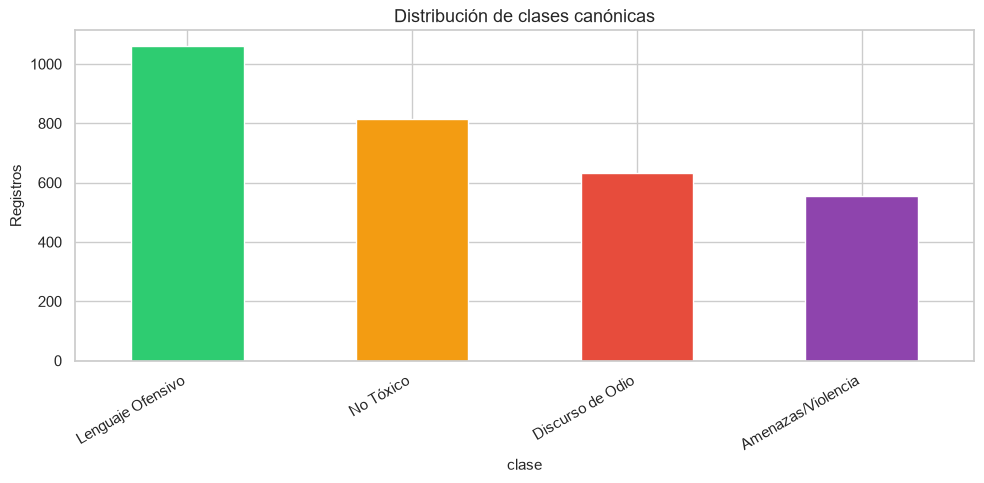

clase
Lenguaje Ofensivo     1060
No Tóxico              815
Discurso de Odio       632
Amenazas/Violencia     556
Name: count, dtype: int64

In [4]:
class_dist = corpus['clase'].value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
class_dist.plot(kind='bar', color=get_class_palette(), ax=ax)
ax.set_title('Distribución de clases canónicas')
ax.set_ylabel('Registros')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / '01_distribucion_clases.png')
plt.show()
class_dist


## 3.1 Pisos de referencia sin modelo


In [5]:
from discurso_odio.evaluation.metrics import trivial_baselines
counts = corpus['label'].value_counts().to_dict()
baselines = trivial_baselines(counts)
pd.Series(baselines, name='F1-macro').to_frame()


,F1-macro
azar_estratificado,0.250
azar_uniforme,0.250
clase_mayoritaria,0.087


## 4. Análisis cross-platform


In [6]:
from scipy.stats import chi2_contingency, mannwhitneyu

ct = pd.crosstab(corpus['Plataforma'], corpus['clase'])
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.sum().sum()
cramers_v = (chi2 / (n * (min(ct.shape) - 1))) ** 0.5

x_len = corpus[corpus['Plataforma']=='X']['n_palabras']
fb_len = corpus[corpus['Plataforma']=='Facebook']['n_palabras']
u_stat, u_p = mannwhitneyu(x_len, fb_len, alternative='two-sided')

pd.DataFrame({
    'prueba': ['Chi-cuadrado', 'V de Cramér', 'Mann-Whitney U (longitud)'],
    'estadistico': [f'{chi2:.1f}', f'{cramers_v:.3f}', f'{u_stat:.0f}'],
    'p_valor': [f'{p:.2e}', '-', f'{u_p:.2e}'],
})


,prueba,estadistico,p_valor
0,Chi-cuadrado,135.9,2.86e-29
1,V de Cramér,0.211,-
2,Mann-Whitney U (longitud),1590274,2.24e-65


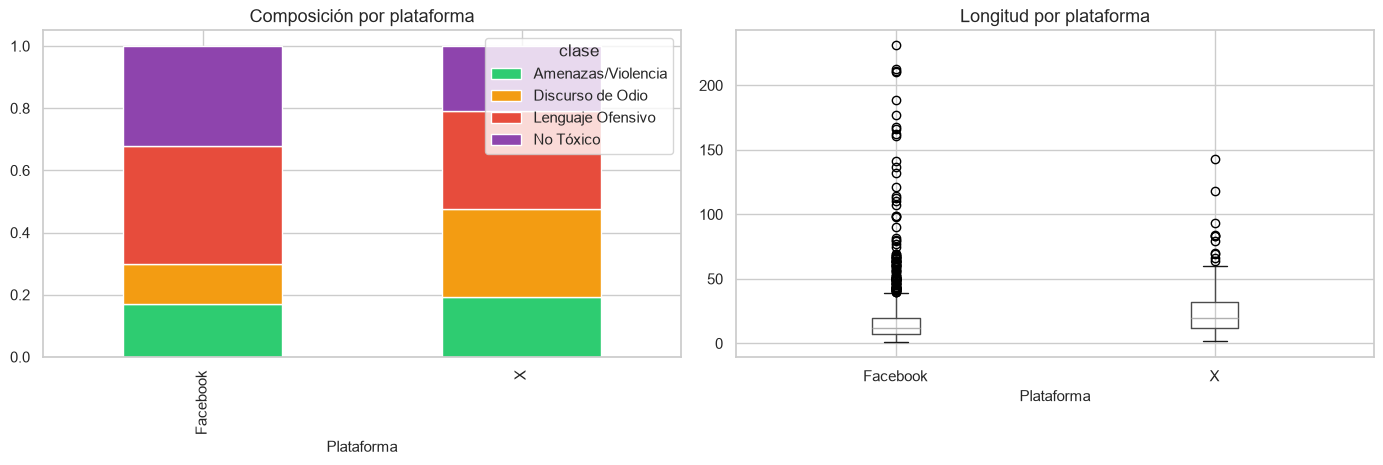

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.crosstab(corpus['Plataforma'], corpus['clase'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[0], color=get_class_palette())
axes[0].set_title('Composición por plataforma')
corpus.boxplot(column='n_palabras', by='Plataforma', ax=axes[1])
axes[1].set_title('Longitud por plataforma')
plt.suptitle('')
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / '02_plataforma_clases.png')
plt.show()


## 5. Caracterización lingüística


In [8]:
dialect_stats = {
    'textos_con_jerga': f"{(corpus['n_jerga']>0).mean()*100:.1f}%",
    'media_jerga': corpus['n_jerga'].mean(),
    'lift_toxicidad_jerga': (
        (corpus[corpus['n_jerga']>0]['label']>0).mean() /
        max((corpus[corpus['n_jerga']==0]['label']>0).mean(), 1e-9)
    ),
}
pd.Series(dialect_stats, name='valor')


textos_con_jerga           61.7%
media_jerga             1.095005
lift_toxicidad_jerga    1.789015
Name: valor, dtype: object

## 7. Tokenización mBERT — cobertura max_length


Percentil 99 tokens: 95 | max_length configurado: 128


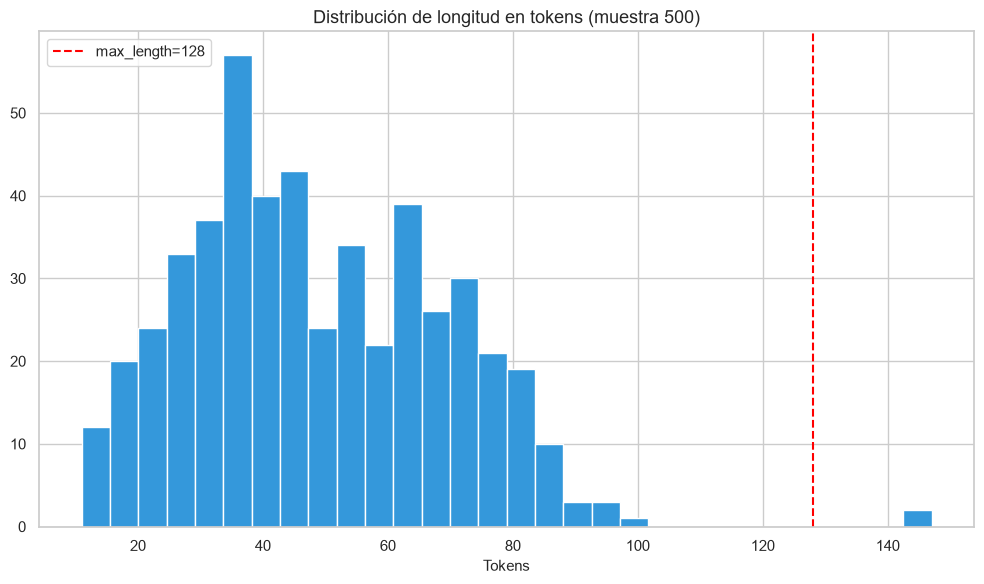

In [9]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(settings['model']['name'])
lengths = [len(tokenizer.encode(t, add_special_tokens=True)) for t in corpus['texto_modelo'].head(500)]
p99 = np.percentile(lengths, 99)
print(f'Percentil 99 tokens: {p99:.0f} | max_length configurado: {settings["model"]["max_length"]}')
plt.hist(lengths, bins=30, color='#3498db', edgecolor='white')
plt.axvline(settings['model']['max_length'], color='red', linestyle='--', label='max_length=128')
plt.title('Distribución de longitud en tokens (muestra 500)')
plt.xlabel('Tokens')
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / '03_token_lengths.png')
plt.show()
